# Potato Tuber Dry-Rot Appearance and Severity Classification

This notebook presents the completed four-class experiment from saved artifacts. It does not retrain models or rerun test inference. Labels are the dataset's visual grades, not laboratory-confirmed disease diagnoses. The dataset has no verified physical-tuber IDs; results are based on the documented inferred capture groups and retain that limitation.

## Dataset, classes, and frozen split

Source: Mendeley Data, DOI 10.17632/rgn2d2jb7f.1, CC BY 4.0. The experiment uses Asterix, Diamant, and Lal Pakri. Rumana, Scab, and Fully-Rotten are excluded. Eight samples were quarantined with contradictory inferred capture components before splitting. The remaining 6,329 images use seed 42 and a frozen grouped split. The grouping does not establish independent physical tubers.

In [1]:
import csv, json
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/manifests/candidate_a').exists()), Path.cwd())
OUT = ROOT / 'outputs/experiments'
summary = json.loads((ROOT/'data/manifests/candidate_a/preparation_summary.json').read_text())
print('Images:', summary['usable_images'], '| inferred groups:', summary['inferred_groups'], '| seed:', summary['seed'])
print('Verified physical tuber count:', summary['verified_physical_tuber_count'])
for split, counts in summary['class_counts'].items():
    print(split, sum(counts.values()), counts)

Images: 6329 | inferred groups: 614 | seed: 42
Verified physical tuber count: UNKNOWN
train 4706 {'Healthy': 1425, 'DryRot-Mild': 185, 'DryRot-Moderate': 789, 'DryRot-Severe': 2307}
validation 760 {'Healthy': 56, 'DryRot-Mild': 51, 'DryRot-Moderate': 173, 'DryRot-Severe': 480}
test 863 {'Healthy': 190, 'DryRot-Mild': 41, 'DryRot-Moderate': 165, 'DryRot-Severe': 467}


## Model comparison — held-out test set, evaluated once

In [2]:
with (OUT/'three_model_comparison.csv').open(newline='') as f:
    rows = list(csv.DictReader(f))
for r in rows:
    print(f"{r['model']:18} accuracy={float(r['test_accuracy']):.3f} macro-F1={float(r['test_macro_f1']):.3f} weighted-F1={float(r['test_weighted_f1']):.3f}")

Custom CNN         accuracy=0.771 macro-F1=0.592 weighted-F1=0.768
EfficientNetV2-S   accuracy=0.771 macro-F1=0.654 weighted-F1=0.794
ViT-B/16           accuracy=0.826 macro-F1=0.700 weighted-F1=0.833


## Per-class test metrics

In [3]:
from IPython.display import display, HTML
rows = []
for model in ['custom_cnn','efficientnet_v2_s','vit_b_16']:
    result = json.loads((OUT/model/'test_metrics.json').read_text())
    for r in result['per_class']:
        rows.append(f"<tr><td>{model}</td><td>{r['class_name']}</td><td>{r['precision']:.3f}</td><td>{r['recall']:.3f}</td><td>{r['f1']:.3f}</td><td>{r['support']}</td></tr>")
display(HTML('<table><tr><th>Model</th><th>Class</th><th>Precision</th><th>Recall</th><th>F1</th><th>Support</th></tr>'+''.join(rows)+'</table>'))

Model,Class,Precision,Recall,F1,Support
custom_cnn,Healthy,1.000,0.800,0.889,190
custom_cnn,DryRot-Mild,0.188,0.073,0.105,41
custom_cnn,DryRot-Moderate,0.458,0.558,0.503,165
custom_cnn,DryRot-Severe,0.846,0.895,0.870,467
efficientnet_v2_s,Healthy,1.000,0.805,0.892,190
efficientnet_v2_s,DryRot-Mild,0.200,0.439,0.275,41
efficientnet_v2_s,DryRot-Moderate,0.528,0.630,0.575,165
efficientnet_v2_s,DryRot-Severe,0.922,0.835,0.876,467
vit_b_16,Healthy,1.000,0.921,0.959,190
vit_b_16,DryRot-Mild,0.286,0.390,0.330,41


## Learning curves

train_loss.png


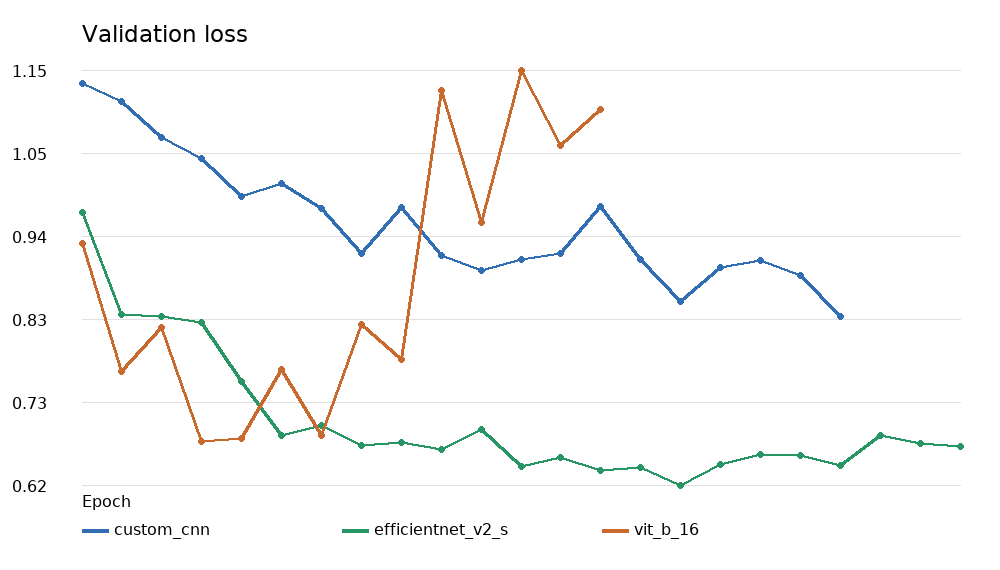

validation_macro_f1.png


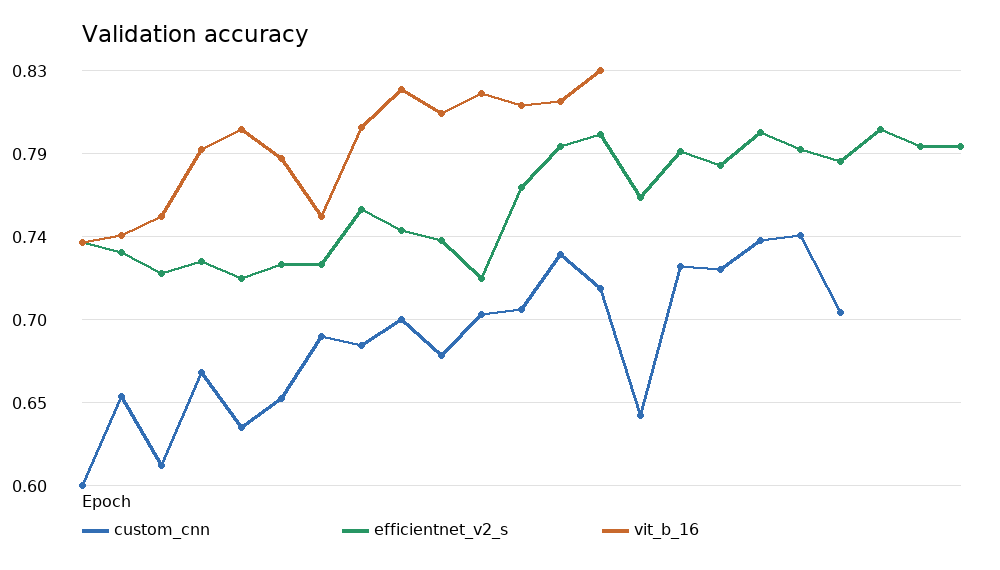

In [4]:
from IPython.display import display, Image
for name in ['train_loss.png','validation_loss.png','validation_macro_f1.png','validation_accuracy.png']:
    print(name); display(Image(filename=str(OUT/name)))

## Confusion matrices

custom_cnn_confusion_matrix.png


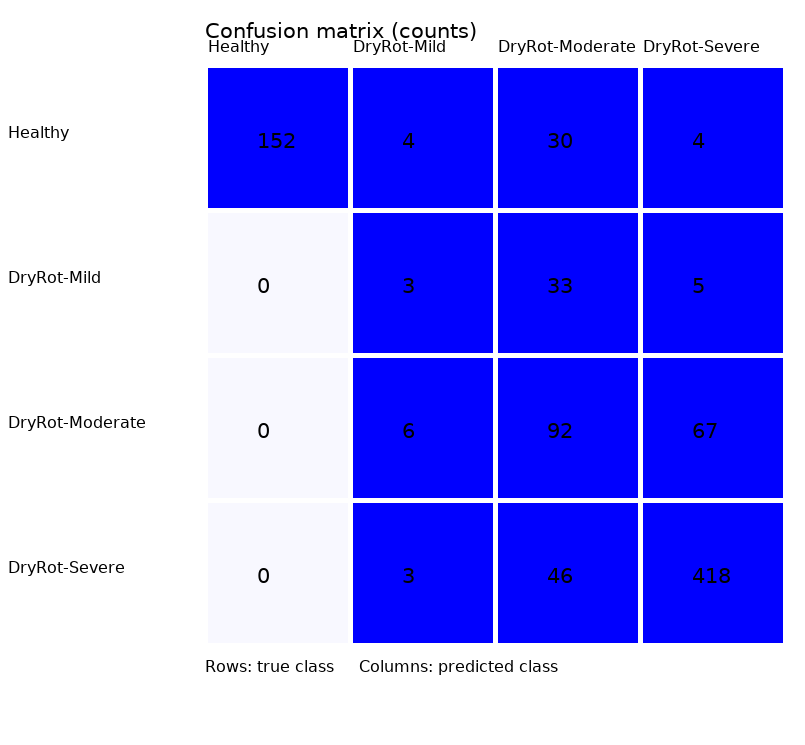

efficientnet_v2_s_confusion_matrix.png


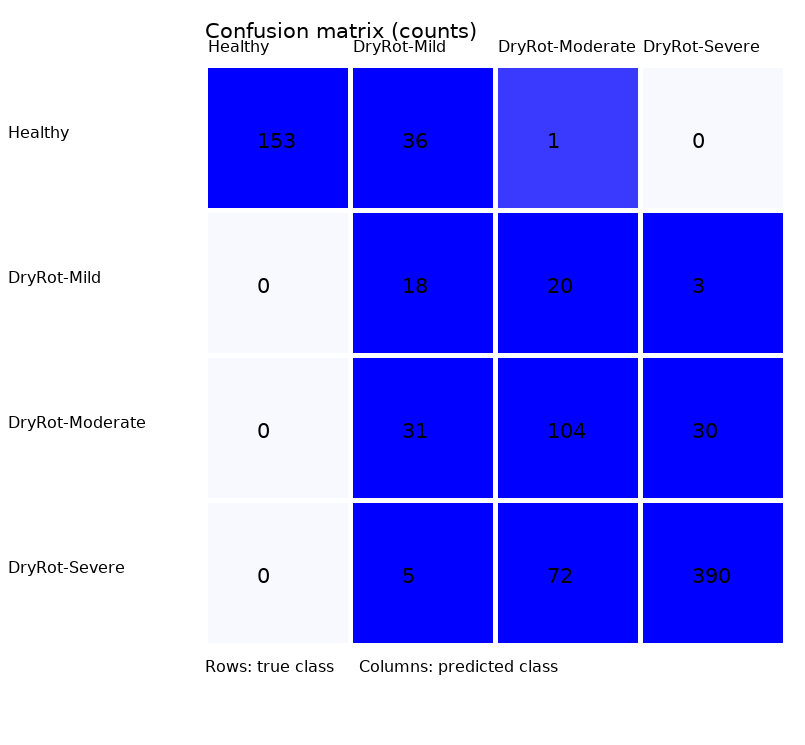

vit_b_16_confusion_matrix.png


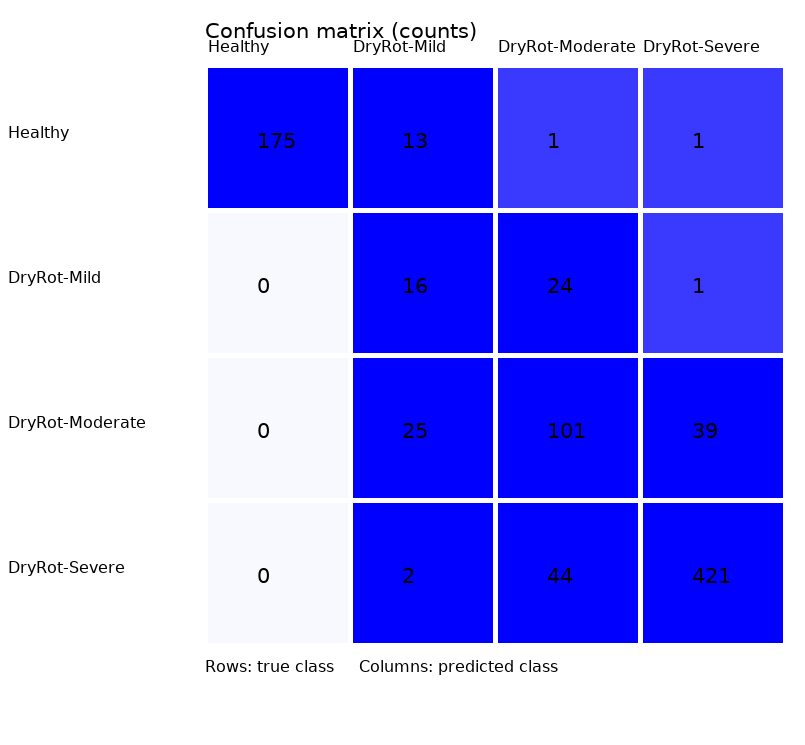

custom_cnn_confusion_matrix_normalized.png


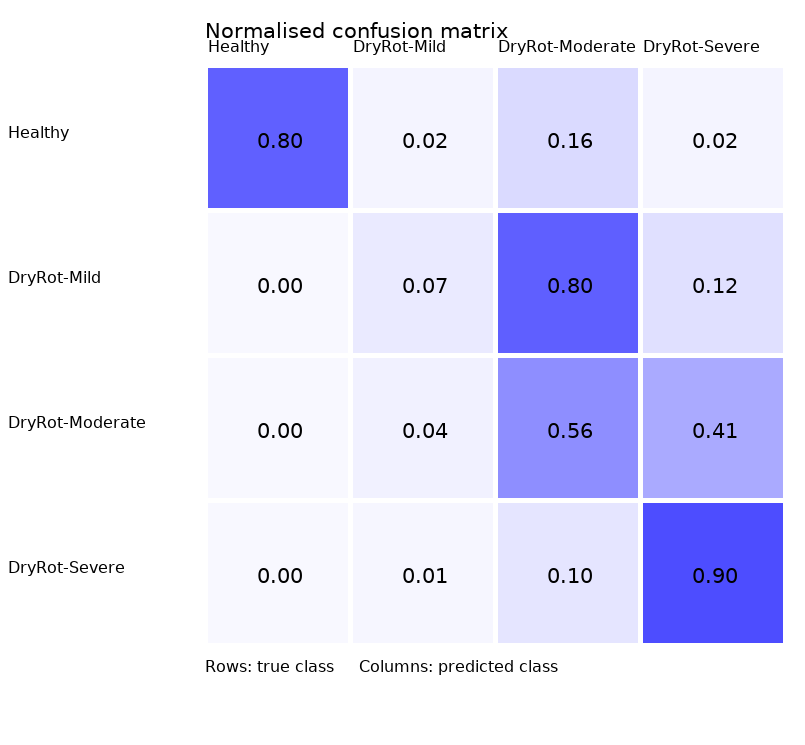

efficientnet_v2_s_confusion_matrix_normalized.png


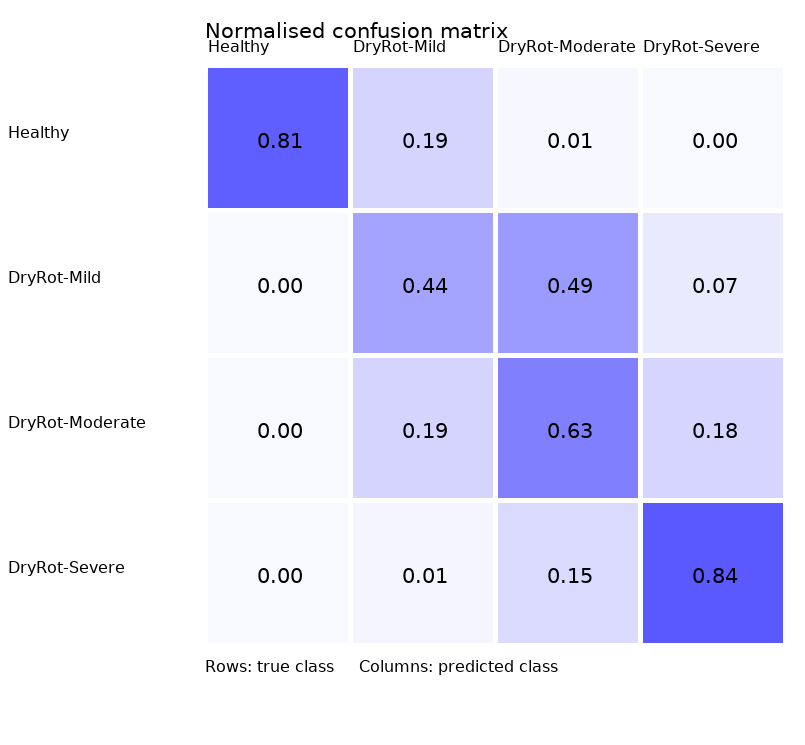

vit_b_16_confusion_matrix_normalized.png


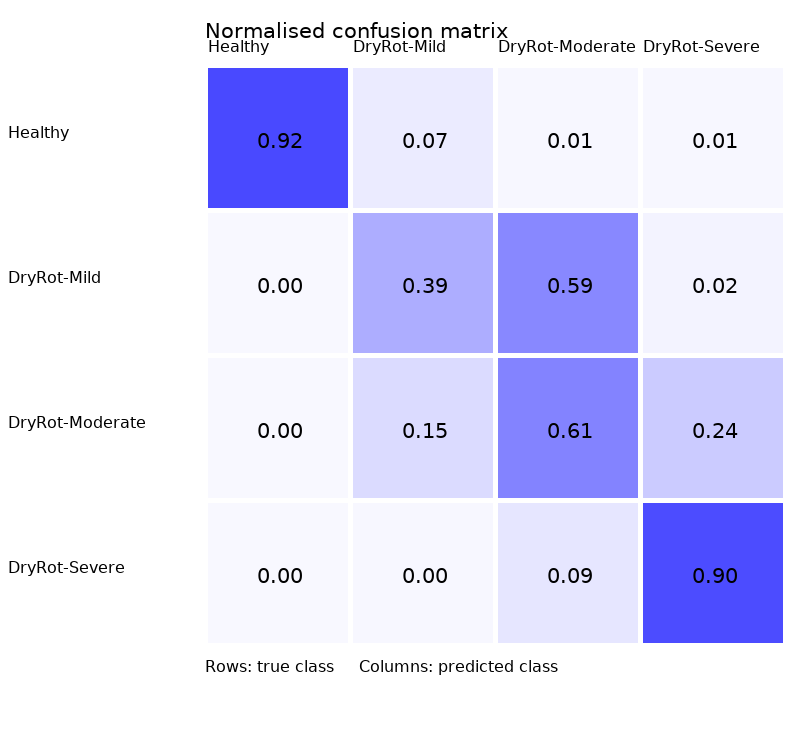

In [5]:
from IPython.display import display, Image
for name in ['custom_cnn_confusion_matrix.png','efficientnet_v2_s_confusion_matrix.png','vit_b_16_confusion_matrix.png',
             'custom_cnn_confusion_matrix_normalized.png','efficientnet_v2_s_confusion_matrix_normalized.png','vit_b_16_confusion_matrix_normalized.png']:
    print(name); display(Image(filename=str(OUT/name)))

## Correct and incorrect ViT test examples

In [6]:
all_rows = {r['image_id']: r for r in csv.DictReader((ROOT/'data/manifests/candidate_a/all.csv').open(newline=''))}
preds = list(csv.DictReader((OUT/'vit_b_16'/'test_predictions.csv').open(newline='')))
for correct in ['True','False']:
    print('Correct predictions' if correct == 'True' else 'Incorrect predictions')
    for r in [x for x in preds if x['correct'] == correct][:8]:
        print(all_rows[r['image_id']]['archive_member'], '| true:', r['true'], '| predicted:', r['predicted'])

Correct predictions
BARI_Alu_25_Asterix__DryRot_Severe/IMG20251109131030.jpg | true: DryRot-Severe | predicted: DryRot-Severe
Lal_Pakri__DryRot_Severe/IMG_20260724_161651.jpg | true: DryRot-Severe | predicted: DryRot-Severe
Lal_Pakri__DryRot_Severe/IMG_20260722_170834.jpg | true: DryRot-Severe | predicted: DryRot-Severe
BARI_Alu_7_Diamant__DryRot_Severe/IMG20251110122034.jpg | true: DryRot-Severe | predicted: DryRot-Severe
BARI_Alu_25_Asterix__DryRot_Severe/IMG20251108133612.jpg | true: DryRot-Severe | predicted: DryRot-Severe
BARI_Alu_25_Asterix__DryRot_Severe/IMG20251109123725.jpg | true: DryRot-Severe | predicted: DryRot-Severe
BARI_Alu_25_Asterix__DryRot_Moderate/IMG_20260722_133647.jpg | true: DryRot-Moderate | predicted: DryRot-Moderate
BARI_Alu_25_Asterix__Healthy/IMG20251111124721.jpg | true: Healthy | predicted: Healthy
Incorrect predictions
BARI_Alu_25_Asterix__DryRot_Moderate/IMG_20260722_130529.jpg | true: DryRot-Moderate | predicted: DryRot-Severe
BARI_Alu_7_Diamant__DryRo

## Main findings and limitations

ViT-B/16 had the strongest test Macro-F1 in this single run. Mild dry rot was the hardest class and was most often confused with Moderate. Performance is descriptive for this fixed split and one run per model. The source provides no verified potato IDs or quantitative severity rubric, and residual grouping uncertainty remains. Refer to `outputs/experiments/COMPLETION_REPORT.md` for complete metrics, classwise results, all-model matrices, reproducibility settings, and the rubric/deliverables audit.